In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import datetime as dt
import seaborn as sns

In [2]:
filepath = "C://Users//dayee//OneDrive//Documents//Analytix Labs//Python//Case studies//Case Study 4 - Python Visualizations Case Study//SalesData.csv"
df = pd.read_csv(filepath)
df.head()

,AccountId,AccountName,Region,Division,City,State,Tier,Month,Sales2015,Sales2016,Units2015,Units2016,TargetAchevied2015,TargetAchevied2016
0,1116,Account1,West,DIAMONDBACK,PHOENIX W,AZ,Low,Aug,0.00,13208.52,0.0,4.0,0.70,1.53
1,1116,Account1,West,DIAMONDBACK,PHOENIX W,AZ,Low,Oct,10500.78,23114.91,3.0,7.0,0.84,1.31
2,2391,Account2,East,MINUTEMEN,HARTFORD,CT,Med,Jun,0.00,6627.00,0.0,3.0,1.15,1.29
3,2391,Account2,East,MINUTEMEN,HARTFORD,CT,Med,Mar,19881.00,13254.00,9.0,6.0,1.33,1.17
4,2397,Account3,East,MINUTEMEN,WORCESTER,MA,Med,Sep,3684.48,0.00,1.0,0.0,1.02,1.53


In [3]:
# Metadata inspection

In [4]:
df.isna().sum()

AccountId             0
AccountName           0
Region                0
Division              0
City                  0
State                 0
Tier                  0
Month                 0
Sales2015             0
Sales2016             0
Units2015             0
Units2016             0
TargetAchevied2015    0
TargetAchevied2016    0
dtype: int64

In [5]:
df.shape

(3709, 14)

In [6]:
df.size

51926

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3709 entries, 0 to 3708
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   AccountId           3709 non-null   int64  
 1   AccountName         3709 non-null   object 
 2   Region              3709 non-null   object 
 3   Division            3709 non-null   object 
 4   City                3709 non-null   object 
 5   State               3709 non-null   object 
 6   Tier                3709 non-null   object 
 7   Month               3709 non-null   object 
 8   Sales2015           3709 non-null   float64
 9   Sales2016           3709 non-null   float64
 10  Units2015           3709 non-null   float64
 11  Units2016           3709 non-null   float64
 12  TargetAchevied2015  3709 non-null   float64
 13  TargetAchevied2016  3709 non-null   float64
dtypes: float64(6), int64(1), object(7)
memory usage: 405.8+ KB


In [8]:
#1. Compare Sales by region for 2016 with 2015 using bar chart

In [9]:
df1 = df[['Region', 'Sales2015', 'Sales2016']]
agg1 = df1.pivot_table(index = ['Region'], values = ['Sales2015', 'Sales2016'],
                       aggfunc = {'Sales2015':'sum','Sales2016':'sum'}).reset_index()
agg1

,Region,Sales2015,Sales2016
0,Central,7.891729e+06,9.787809e+06
1,East,9.512916e+06,1.266723e+07
2,West,5.349745e+06,7.209689e+06


In [10]:
agg1.set_index('Region',inplace = True)
agg1

,Sales2015,Sales2016
Region,,
Central,7.891729e+06,9.787809e+06
East,9.512916e+06,1.266723e+07
West,5.349745e+06,7.209689e+06


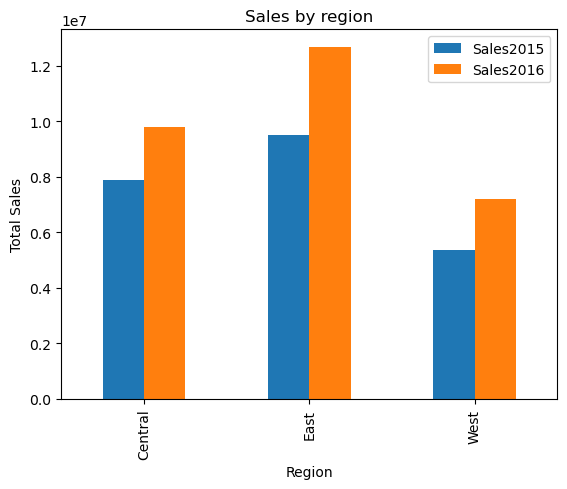

In [11]:
agg1.plot(kind = 'bar')
plt.title('Sales by region')
plt.xlabel('Region')
plt.ylabel('Total Sales')
plt.show()

In [12]:
#2. What are the contributing factors to the sales for each region in 2016. Visualize it using a Pie Chart.

In [13]:
agg2 = df.pivot_table(index = ['Region'], values = ['Sales2016'], aggfunc = 'sum')
agg2

,Sales2016
Region,
Central,9.787809e+06
East,1.266723e+07
West,7.209689e+06


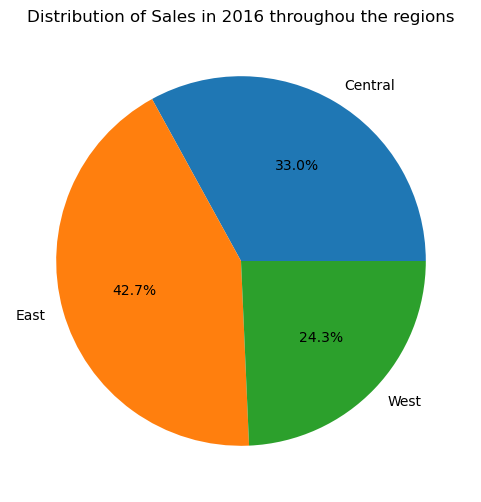

In [14]:
plt.figure(figsize = (6,6))
plt.title('Distribution of Sales in 2016 throughou the regions')
plt.pie(agg2['Sales2016'], labels = agg2.index, autopct = '%1.1f%%')
plt.show()

In [15]:
#3. Compare the total sales of 2015 and 2016 with respect to Region and Tiers

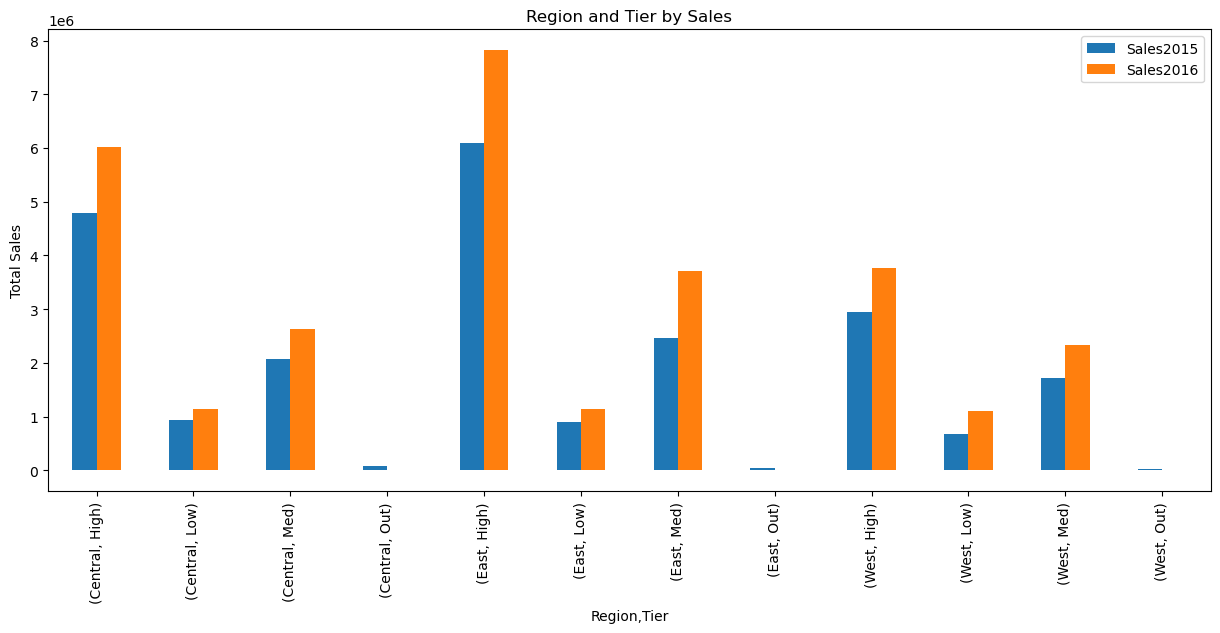

In [16]:
agg3 = df.pivot_table(index = ['Region', 'Tier'], values = ['Sales2015', 'Sales2016'], aggfunc = 'sum')
agg3.plot(kind = 'bar', figsize = (15,6))
plt.title('Region and Tier by Sales')
plt.ylabel('Total Sales')
plt.show()

In [17]:
#4. In East region, which state registered a decline in 2016 as compared to 2015?

In [18]:
#df4 = df.loc[df['Region'] == 'East', ['State', 'Sales2016', 'Sales2015']].reset_index()
df4.drop(columns = 'index', inplace = True)
df4

NameError: name 'df4' is not defined

In [ ]:
agg4 = df4.pivot_table(index = ['State'], values = ['Sales2016', 'Sales2015'], aggfunc = 'sum')

In [ ]:
agg4.plot(kind = 'bar', figsize = (15,6))
plt.title('Sales in 2015 and 2016 by States in the East region')
plt.ylabel('Total Sales')
plt.show()

In [ ]:
#5. In all the High tier, which Division saw a decline in number of units sold in 2016 compared to 2015

In [ ]:
df5 = df.loc[df['Tier'] == 'High', ['Division', 'Units2015', 'Units2016']]
agg5 = df5.pivot_table(index = ['Division'], values = ['Units2015', 'Units2016'], aggfunc = 'sum')
agg5

In [ ]:
agg5.plot(kind = 'bar', figsize = (15,6))
plt.title('Units Sold in 2015 and 2016 in each Division in the High Tier')
plt.ylabel('Units Sold')
plt.show()

In [ ]:
"""
6. Create a new column Qtr using numpy.where() or any suitable utility in the imported dataset. The Quarters are based on months and defined as -
• Jan - Mar : Q1
• Apr - Jun : Q2
• Jul - Sep : Q3
• Oct - Dec : Q4
"""

In [24]:
quarter_map = {'Jan': 'Q1', 'Feb': 'Q1', 'Mar': 'Q1',
               'Apr': 'Q2', 'May': 'Q2', 'Jun': 'Q2',
               'Jul': 'Q3', 'Aug': 'Q3', 'Sep': 'Q3',
               'Oct': 'Q4', 'Nov': 'Q4', 'Dec': 'Q4'}
df['Qtr'] = df['Month'].map(quarter_map)
df.head()

,AccountId,AccountName,Region,Division,City,State,Tier,Month,Sales2015,Sales2016,Units2015,Units2016,TargetAchevied2015,TargetAchevied2016,Qtr
0,1116,Account1,West,DIAMONDBACK,PHOENIX W,AZ,Low,Aug,0.00,13208.52,0.0,4.0,0.70,1.53,Q3
1,1116,Account1,West,DIAMONDBACK,PHOENIX W,AZ,Low,Oct,10500.78,23114.91,3.0,7.0,0.84,1.31,Q4
2,2391,Account2,East,MINUTEMEN,HARTFORD,CT,Med,Jun,0.00,6627.00,0.0,3.0,1.15,1.29,Q2
3,2391,Account2,East,MINUTEMEN,HARTFORD,CT,Med,Mar,19881.00,13254.00,9.0,6.0,1.33,1.17,Q1
4,2397,Account3,East,MINUTEMEN,WORCESTER,MA,Med,Sep,3684.48,0.00,1.0,0.0,1.02,1.53,Q3


In [25]:
#7. Compare Qtr wise sales in 2015 and 2016 in a bar plot

In [27]:
agg7 = df.pivot_table(index = ['Qtr'], values = ['Sales2015', 'Sales2016'], aggfunc = 'sum')
agg7

,Sales2015,Sales2016
Qtr,,
Q1,5.485800e+06,6.997953e+06
Q2,5.390862e+06,7.237361e+06
Q3,6.164094e+06,7.861546e+06
Q4,5.713634e+06,7.567868e+06


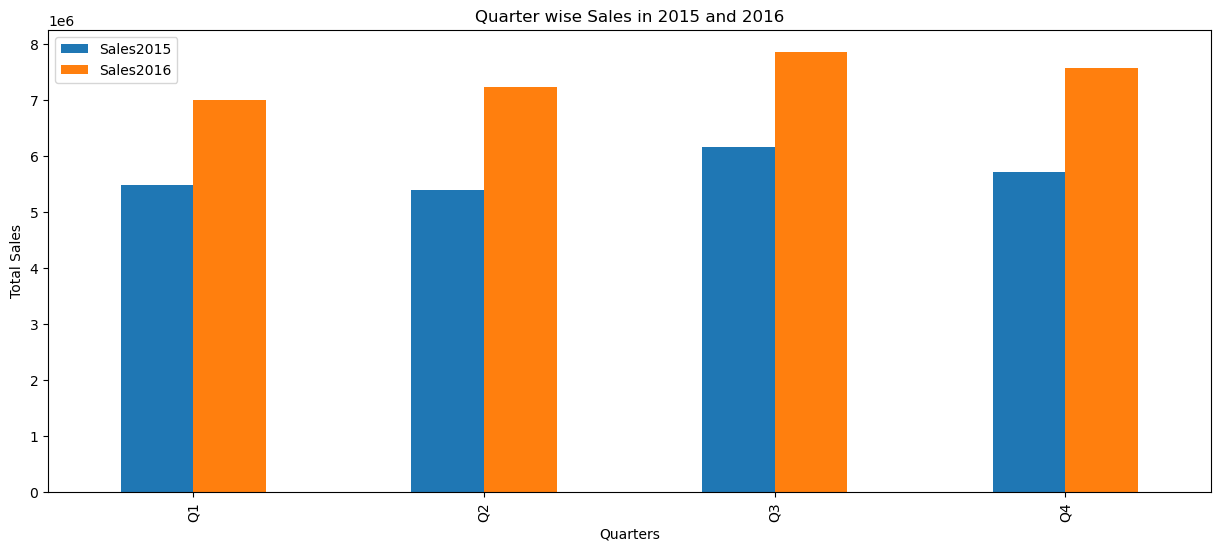

In [30]:
agg7.plot(kind = 'bar', figsize = (15,6))
plt.title('Quarter wise Sales in 2015 and 2016')
plt.xlabel('Quarters')
plt.ylabel('Total Sales')
plt.show()

In [31]:
"""
8. Determine the composition of Qtr wise sales in and 2016 with regards to all the Tiers in a pie chart. 
(Draw 4 pie charts representing a Quarter for each Tier)
"""

'\n8. Determine the composition of Qtr wise sales in and 2016 with regards to all the Tiers in a pie chart. \n(Draw 4 pie charts representing a Quarter for each Tier)\n'

In [44]:
df81 = df.loc[df['Qtr'] == 'Q1', ['Tier', 'Sales2016']].reset_index()

In [46]:
df81.drop(columns = ['index'], inplace = True)

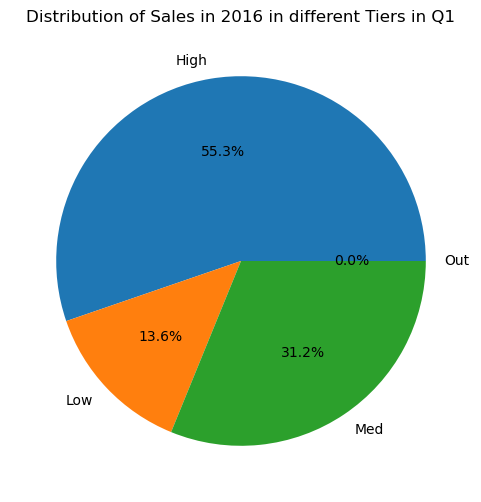

In [52]:
agg81 = df81.pivot_table(index = ['Tier'], values = ['Sales2016'], aggfunc = 'sum')
plt.figure(figsize = (6,6))
plt.title('Distribution of Sales in 2016 in different Tiers in Q1')
plt.pie(agg81['Sales2016'], labels = agg81.index, autopct = '%1.1f%%')
plt.show()

In [53]:
df82 = df.loc[df['Qtr'] == 'Q2', ['Tier', 'Sales2016']].reset_index()

In [55]:
df82.drop(columns = ['index'], inplace = True)

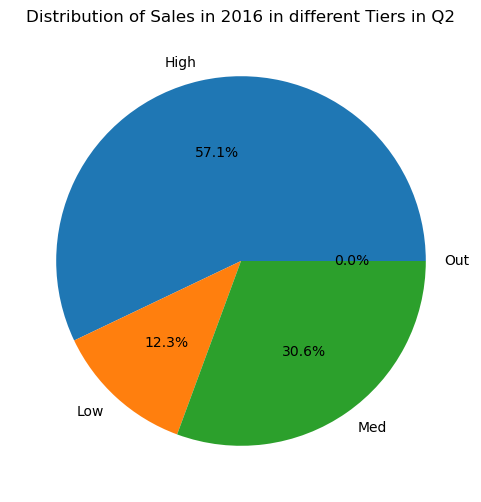

In [63]:
agg82 = df82.pivot_table(index = ['Tier'], values = ['Sales2016'], aggfunc = 'sum')
plt.figure(figsize = (6,6))
plt.title('Distribution of Sales in 2016 in different Tiers in Q2')
plt.pie(agg82['Sales2016'], labels = agg82.index, autopct = '%1.1f%%')
plt.show()

In [59]:
df83 = df.loc[df['Qtr'] == 'Q3', ['Tier', 'Sales2016']].reset_index()

In [61]:
df83.drop(columns = ['index'], inplace = True)

In [71]:
#agg83 = df83.pivot_table(index = ['Tier'], values = ['Sales2016'], aggfunc = 'sum')
#agg83 = df83.groupby(by = ['Tier']).agg(TotSales = ('Sales2016', 'sum'))


,TotSales
Tier,
High,4.872559e+06
Low,7.951777e+05
Med,2.197058e+06
Out,-3.248530e+03


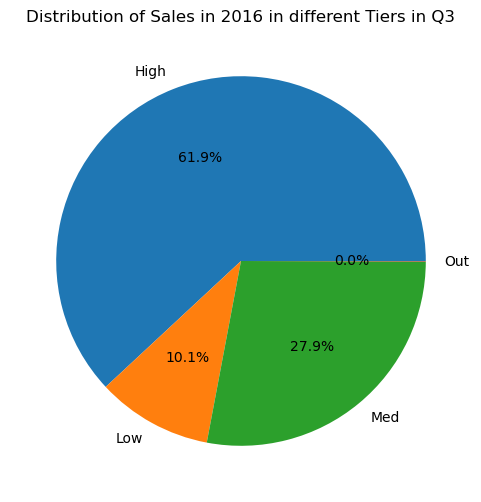

In [73]:
plt.figure(figsize = (6,6))
plt.title('Distribution of Sales in 2016 in different Tiers in Q3')
plt.pie(abs(agg83['TotSales']), labels = agg83.index, autopct = '%1.1f%%')
plt.show()

In [74]:
df84 = df.loc[df['Qtr'] == 'Q4', ['Tier', 'Sales2016']].reset_index()

In [75]:
df84.drop(columns = ['index'], inplace = True)

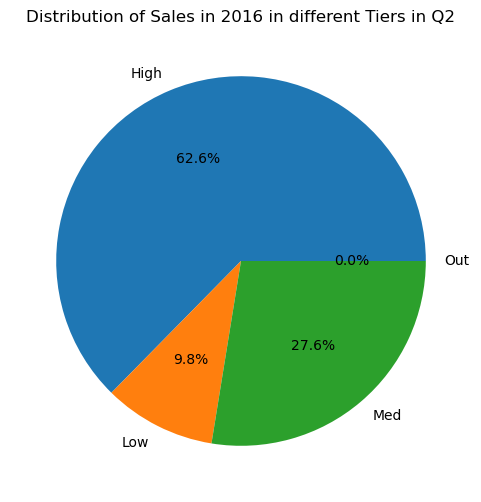

In [76]:
agg84 = df84.pivot_table(index = ['Tier'], values = ['Sales2016'], aggfunc = 'sum')
plt.figure(figsize = (6,6))
plt.title('Distribution of Sales in 2016 in different Tiers in Q2')
plt.pie(agg84['Sales2016'], labels = agg84.index, autopct = '%1.1f%%')
plt.show()